In [1]:
#cloning repo
import os
from pathlib import Path

REPO = Path("/content/loan-default-mlbd")

if not REPO.exists():
    !git clone https://github.com/kratipatel/loan-default-mlbd.git {REPO}

%cd /content/loan-default-mlbd

print("Repository:", os.getcwd())
print("src exists:", Path("src").is_dir())
print("prepare_data exists:", Path("src/prepare_data.py").is_file())

Cloning into '/content/loan-default-mlbd'...
remote: Enumerating objects: 107, done.
remote: Counting objects: 100% (107/107), done.
remote: Compressing objects: 100% (85/85), done.
remote: Total 107 (delta 38), reused 66 (delta 15), pack-reused 0 (from 0)
Receiving objects: 100% (107/107), 1.34 MiB | 20.48 MiB/s, done.
Resolving deltas: 100% (38/38), done.
/content/loan-default-mlbd
Repository: /content/loan-default-mlbd
src exists: True
prepare_data exists: True


In [2]:
%pip install -q pandas numpy pyarrow scikit-learn

In [3]:
!python -m src.prepare_data

from pathlib import Path
DATA_PATH = Path("data/processed/loans_clean.parquet")
assert DATA_PATH.is_file(), f"Dataset was not created: {DATA_PATH}"
print("Verified dataset:", DATA_PATH.resolve())
print("Size (MB):", round(DATA_PATH.stat().st_size / (1024 * 1024), 2))

reading: https://raw.githubusercontent.com/tiwvis/MLBD-Projects/main/data_sets/LoansData_sample.csv.gz
saved: /content/loan-default-mlbd/data/processed/loans_clean.parquet (86141, 71)
        size      mean
split                 
test   12922  0.187587
train  60298  0.187585
val    12921  0.187602
Verified dataset: /content/loan-default-mlbd/data/processed/loans_clean.parquet
Size (MB): 6.87


In [5]:
from google.colab import files
uploaded = files.upload()

Saving results_flash.json to results_flash.json
Saving results_fastai.json to results_fastai.json
Saving results_keras.json to results_keras.json
Saving results_tabnet.json to results_tabnet.json


In [7]:
import os
import shutil

os.makedirs("reports", exist_ok=True)

for filename in uploaded:
    shutil.move(filename, os.path.join("reports", filename))

print("Uploaded result files:")
print(os.listdir("reports"))

Uploaded result files:
['figures', 'results_flash.json', 'results_keras.json', 'leakage_audit.md', 'results_xgboost.json', 'results_tabnet.json', 'results_fastai.json']


In [8]:
import os

print("Checking result files...")

files = [
    "results_xgboost.json",
    "results_keras.json",
    "results_fastai.json",
    "results_tabnet.json",
    "results_flash.json"
]

for f in files:
    path = os.path.join("reports", f)
    print(f, "FOUND" if os.path.exists(path) else "MISSING")

Checking result files...
results_xgboost.json FOUND
results_keras.json FOUND
results_fastai.json FOUND
results_tabnet.json FOUND
results_flash.json FOUND


In [9]:
import json
import os
import pandas as pd

frameworks = ["xgboost", "keras", "fastai", "tabnet", "flash"]

results = {}

for framework in frameworks:
    path = f"reports/results_{framework}.json"

    with open(path, "r") as f:
        results[framework] = json.load(f)

print("All result files loaded successfully!")

for framework, data in results.items():
    print(f"\n{framework.upper()}")
    print(data.keys())

All result files loaded successfully!

XGBOOST
dict_keys(['framework', 'params', 'train_seconds', 'val', 'test'])

KERAS
dict_keys(['validation', 'test', 'training_time_seconds'])

FASTAI
dict_keys(['validation', 'test', 'training_time_seconds'])

TABNET
dict_keys(['framework', 'params', 'train_seconds', 'val', 'test'])

FLASH
dict_keys(['framework', 'params', 'train_seconds', 'val', 'test'])


In [10]:
import pandas as pd

rows = []

for framework, data in results.items():

    val = data.get("val", data.get("validation"))
    test = data["test"]
    train_time = data.get("train_seconds", data.get("training_time_seconds"))

    for split_name, metrics in [("Validation", val), ("Test", test)]:
        rows.append({
            "Framework": framework.upper(),
            "Split": split_name,
            "RMSE": metrics["rmse"],
            "MAE": metrics["mae"],
            "R2": metrics["r2"],
            "ROC-AUC": metrics["roc_auc"],
            "PR-AUC": metrics["pr_auc"],
            "KS": metrics["ks"],
            "Training Time (s)": train_time
        })

comparison_df = pd.DataFrame(rows)

print("Comparison data created!")
display(comparison_df.round(4))

Comparison data created!


,Framework,Split,RMSE,MAE,R2,ROC-AUC,PR-AUC,KS,Training Time (s)
0,XGBOOST,Validation,0.3659,0.2681,0.1214,0.7402,0.4022,0.3490,16.6000
1,XGBOOST,Test,0.3676,0.2710,0.1131,0.7337,0.3890,0.3476,16.6000
2,KERAS,Validation,0.3670,0.2691,0.1161,0.7368,0.3971,0.3387,24.6800
3,KERAS,Test,0.3686,0.2719,0.1087,0.7330,0.3898,0.3460,24.6800
4,FASTAI,Validation,0.3745,0.2630,0.0799,0.7169,0.3655,0.3186,28.1700
5,FASTAI,Test,0.3769,0.2674,0.0680,0.7058,0.3612,0.3023,28.1700
6,TABNET,Validation,0.3677,0.2800,0.1128,0.7338,0.3957,0.3354,129.3068
7,TABNET,Test,0.3693,0.2828,0.1051,0.7296,0.3829,0.3437,129.3068
8,FLASH,Validation,0.3730,0.2766,0.0873,0.7098,0.3488,0.3101,220.9980
9,FLASH,Test,0.3739,0.2785,0.0828,0.7038,0.3477,0.3009,220.9980


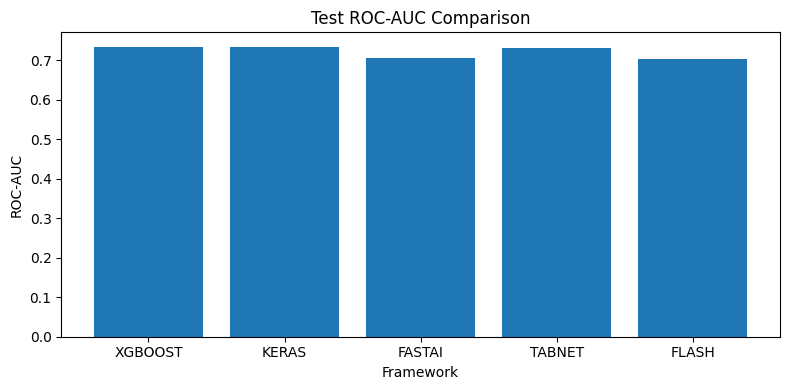

----------------------------------------------------------------------------------------------------


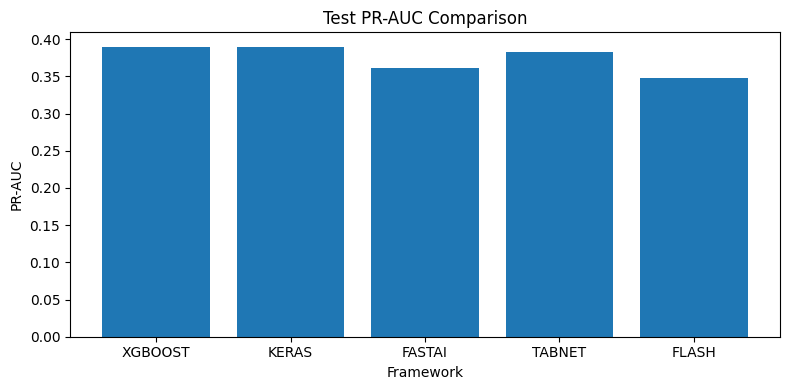

----------------------------------------------------------------------------------------------------


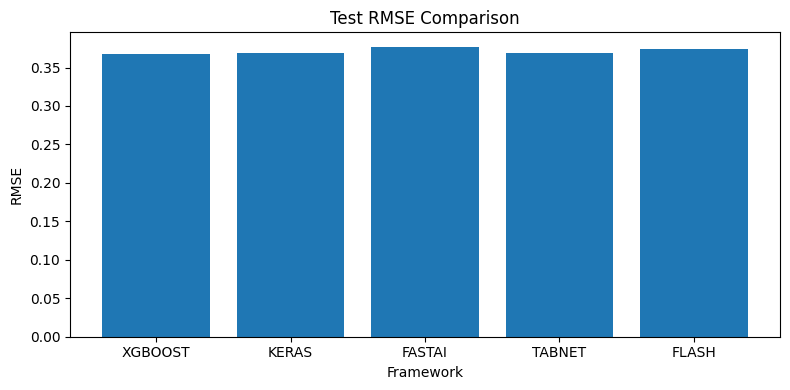

----------------------------------------------------------------------------------------------------


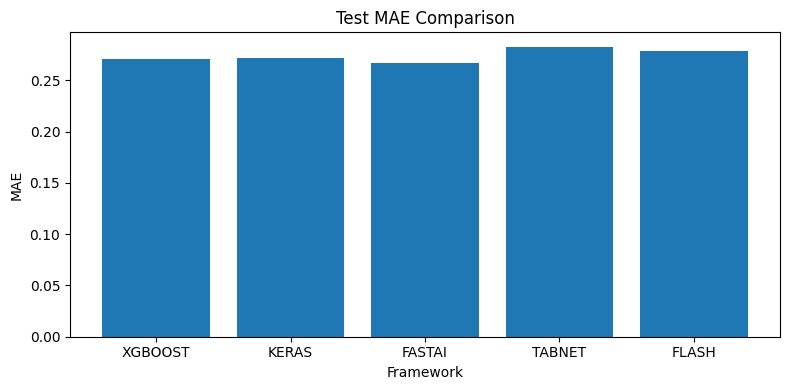

----------------------------------------------------------------------------------------------------


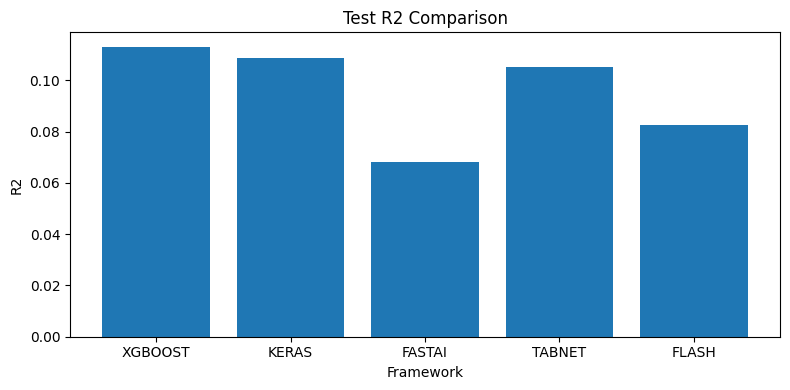

----------------------------------------------------------------------------------------------------


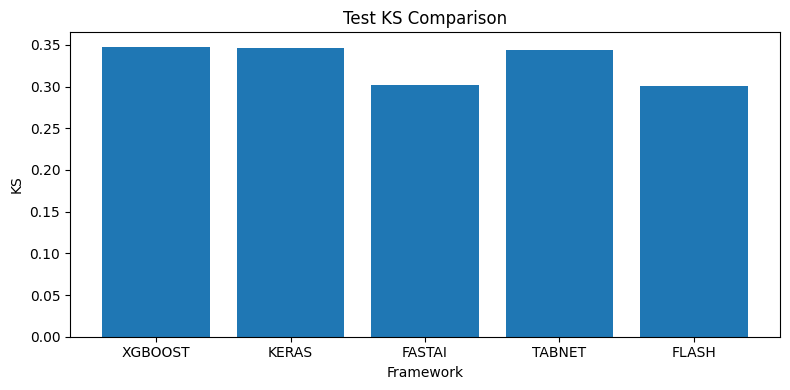

In [12]:
import matplotlib.pyplot as plt

test_df = comparison_df[comparison_df["Split"] == "Test"].copy()

metrics = ["ROC-AUC", "PR-AUC", "RMSE", "MAE", "R2", "KS"]

for i, metric in enumerate(metrics):
    plt.figure(figsize=(8, 4))
    plt.bar(test_df["Framework"], test_df[metric])
    plt.title(f"Test {metric} Comparison")
    plt.xlabel("Framework")
    plt.ylabel(metric)
    plt.tight_layout()
    plt.show()

    if i < len(metrics) - 1:
        print("-" * 100)

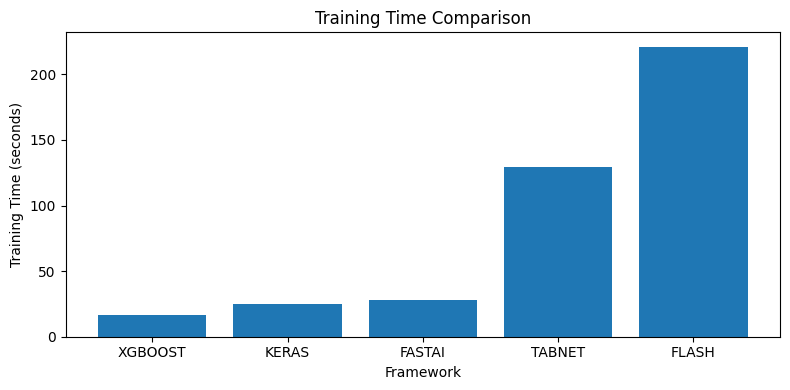

In [13]:
plt.figure(figsize=(8, 4))

plt.bar(test_df["Framework"], test_df["Training Time (s)"])

plt.title("Training Time Comparison")
plt.xlabel("Framework")
plt.ylabel("Training Time (seconds)")

plt.tight_layout()
plt.show()

In [14]:
comparison_df.to_csv("reports/framework_comparison.csv", index=False)
print("Comparison table saved successfully!")

Comparison table saved successfully!


In [15]:
notes = """
# Machine Learning Framework Comparison

## 1. Overview

Five machine learning frameworks were evaluated for predicting loan default:
XGBoost, Keras, fastai, PyTorch TabNet, and Lightning Flash.

All frameworks were evaluated using the same train, validation, and test
splits. Model selection and tuning were performed using validation data.
Final performance was assessed using the test set.

## 2. Test Performance Comparison

| Framework | RMSE | MAE | R2 | ROC-AUC | PR-AUC | KS |
|---|---:|---:|---:|---:|---:|---:|
| XGBoost | 0.3676 | 0.2710 | 0.1131 | 0.7337 | 0.3890 | 0.3476 |
| Keras | 0.3686 | 0.2719 | 0.1087 | 0.7330 | 0.3898 | 0.3460 |
| fastai | 0.3769 | 0.2674 | 0.0680 | 0.7058 | 0.3612 | 0.3023 |
| TabNet | 0.3693 | 0.2828 | 0.1051 | 0.7296 | 0.3829 | 0.3437 |
| Lightning Flash | 0.3739 | 0.2785 | 0.0828 | 0.7038 | 0.3477 | 0.3009 |

## 3. Training Time Comparison

| Framework | Training Time (seconds) |
|---|---:|
| XGBoost | 16.60 |
| Keras | 24.68 |
| fastai | 28.17 |
| TabNet | 129.31 |
| Lightning Flash | 221.00 |

XGBoost had the shortest training time, while Lightning Flash required
the longest training time among the five implementations.

## 4. Performance Analysis

- XGBoost achieved the highest test ROC-AUC of 0.7337 and the lowest
  test RMSE of 0.3676.
- Keras achieved the highest test PR-AUC of 0.3898.
- TabNet achieved a test ROC-AUC of 0.7296, close to XGBoost and Keras.
- fastai achieved the lowest test MAE of 0.2674, but had lower ROC-AUC
  and R2 than the leading models.
- Lightning Flash had the lowest test ROC-AUC and PR-AUC among the
  evaluated frameworks.

## 5. Simplicity and Transparency

- XGBoost provides a relatively direct workflow for tabular
  classification and supports feature importance analysis.
- Keras provides a high-level API for defining and training neural
  networks.
- fastai provides higher-level abstractions that simplify model training.
- TabNet uses attention-based feature selection, but requires additional
  configuration for categorical features and model parameters.
- Lightning Flash provides a high-level interface, although its
  integration with the tabular dataset and prediction workflow required
  additional environment and API configuration.

## 6. Implementation Experience

- XGBoost, Keras, and fastai completed their implementations successfully.
- TabNet required experimentation with model dimensions and parameters.
- Lightning Flash required additional environment setup and compatibility
  adjustments. The installed Flash version was 0.8.2.
- Flash was also challenging because of its maintenance status and
  compatibility with the surrounding PyTorch ecosystem.

## 7. Overall Conclusion

XGBoost provided the strongest overall balance of test ROC-AUC, RMSE,
and training efficiency in this experiment.

Keras performed very closely to XGBoost and achieved the highest PR-AUC.
TabNet also demonstrated competitive predictive performance, although
its training time was considerably higher.

fastai and Lightning Flash had lower ROC-AUC scores in this experiment.
Lightning Flash also required the longest training time and additional
implementation effort.

The results indicate that framework choice involves trade-offs between
predictive performance, training efficiency, implementation complexity,
and ease of use. No single framework is necessarily best for every
criterion.
"""

os.makedirs("reports", exist_ok=True)

with open("reports/comparison_notes.md", "w", encoding="utf-8") as f:
    f.write(notes)

print("comparison_notes.md created successfully!")

comparison_notes.md created successfully!
